[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-1/blob/main/notebooks/ch13_Lab04_2026_CNN_MNIST_stepwise.ipynb)

**The Why Book of Deep Learning, Part 1** by Dr. Philemon Paul Daniel

**Chapter 13: Convolution: One Small Window** (Part III: Seeing). Also used in Chapters 2, 14, 15.

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-1/read.html?ch=13](https://www.micyaai.com/books/why-deep-learning-1/read.html?ch=13)
* The simplified video course for kids that this book grew from: [aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)

Tested with TensorFlow 2.21 and Keras 3.14. In Colab: *Runtime > Run all*. A GPU runtime makes the bigger
models faster but none of them needs one.

---


# Lab 04 — Seeing Through a CNN
## Convolutional Neural Networks on MNIST, one layer at a time

In Lab 01 we flattened a 28x28 image into 784 numbers and fed it to a single neuron.
That worked, but we threw something away the moment we flattened: **the fact that pixels
have neighbours**. Pixel 100 and pixel 128 are directly above and below each other in the
image, but after flattening they are just two entries 28 apart in a list, no more related
than any other pair.

A **Convolutional Neural Network (CNN)** keeps the grid intact and learns small patterns
that can appear *anywhere* in the image.

### What you will learn

| Concept | Where |
|---|---|
| **Input shape** and why images need a *channel* dimension | Steps 3-4 |
| **Kernels** (filters) - what they are and what they do | Steps 6-7 |
| **Output shape** - why 28x28 becomes 26x26 | Steps 8 and 10 |
| **Channels** - the idea students most often get wrong | Step 11 |
| **Parameter sharing** - why a CNN is smaller than a Dense net | Step 12 |
| **Feature maps** - looking inside every layer | Steps 18-26 |

### The network we will build

Deliberately tiny - **two convolutional layers** and very few filters - so that every
single feature map fits on screen and can be examined individually.

```
Input   (28, 28, 1)
  |
Conv2D(8 filters, 3x3) + ReLU    ->  (26, 26,  8)
MaxPooling2D(2x2)                ->  (13, 13,  8)
  |
Conv2D(16 filters, 3x3) + ReLU   ->  (11, 11, 16)
MaxPooling2D(2x2)                ->  ( 5,  5, 16)
  |
Flatten                          ->  (400,)
Dense(10) + Softmax              ->  (10,)
```

### How to use this notebook

Run the cells in order, top to bottom (`Shift + Enter`). Read the text above each cell
first, then look at what the cell prints or plots. Later cells depend on earlier ones,
so do not skip any.

> **Runtime:** CPU is fine. Training takes about 2-3 minutes.

> ### ✅ Checked edition (November 2026)
> This notebook was re-run top to bottom and checked for *The Why Book of Deep Learning, Part 1*. What changed from the original:
>
> * Added the "Lab 04" title, and corrected the "What you will learn" table, which pointed at the wrong step for output shape, channels and parameter sharing.
> * Training prints one line per epoch (`verbose=2`) instead of thousands of progress-bar updates.
> * Step 25: the learned kernels are about **twice** as large as the random ones (mean |w| 0.29 against 0.14), not "several times".
> * Step 28: after training, `model.summary()` reports a "Total params" of about 15,800 because it includes Adam's state; a line now explains that the model itself has 5,258.
> * `Lab04_CNN_Fundamentals.ipynb` was an earlier copy of this notebook and is not repeated in this set.

---
# Part A - Getting the data into the right shape

---
## Step 1 - Imports

We use TensorFlow's bundled Keras. `layers` gives us the building blocks:
`Conv2D`, `MaxPooling2D`, `Flatten`, `Dense`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Make results repeatable so everyone in the class sees the same numbers
keras.utils.set_random_seed(42)

print("TensorFlow version:", tf.__version__)
print("Keras version     :", keras.__version__)
print("GPU available     :", len(tf.config.list_physical_devices('GPU')) > 0)

TensorFlow version: 2.21.0
Keras version     : 3.14.1


GPU available     : False


---
## Step 2 - Load MNIST and look at the raw shapes

Same dataset as Lab 01: 70,000 handwritten digits, 28x28 pixels, values 0-255.

> **Look for:** `x_train.shape` is `(60000, 28, 28)` - **three** numbers, so three
> dimensions: 60,000 images, each 28 rows by 28 columns. The images are still 2-D grids.
> We are *not* going to flatten them this time.

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print("x_train:", x_train.shape, x_train.dtype)
print("y_train:", y_train.shape, y_train.dtype)
print("x_test :", x_test.shape)
print("y_test :", y_test.shape)

print("\nPixel values range from", x_train.min(), "to", x_train.max())
print("Labels present:", np.unique(y_train))

x_train: (60000, 28, 28) uint8
y_train: (60000,) uint8
x_test : (10000, 28, 28)
y_test : (10000,)

Pixel values range from 0 to 255
Labels present: [0 1 2 3 4 5 6 7 8 9]


---
## Step 3 - The channel dimension (INPUT SHAPE, part 1)

`Conv2D` refuses to accept a `(28, 28)` image. It insists on `(28, 28, 1)`.
That trailing `1` is the **channel** dimension, and it is worth understanding properly.

A **channel** is one complete grid of numbers describing the image in one particular way:

| Image type | Shape | Channels mean |
|---|---|---|
| Grayscale (MNIST) | `(28, 28, 1)` | 1 channel: brightness |
| Colour photo (CIFAR-10) | `(32, 32, 3)` | 3 channels: Red, Green, Blue |
| Satellite / medical | `(256, 256, 12)` | 12 channels: different wavelengths |

So a colour image is really **three stacked grayscale images**. MNIST has just one, but
Keras still wants the slot to be there so the same code works for every case.

The convention `(height, width, channels)` is called **channels-last**, and it is
TensorFlow's default. (PyTorch uses channels-first, `(1, 28, 28)` - a frequent source of
confusion when moving between frameworks.)

`np.expand_dims(..., axis=-1)` inserts a new dimension of size 1 at the end.
`x_train.reshape(-1, 28, 28, 1)` does the same thing.

> **Important:** this changes *no data at all*. 47,040,000 pixel values before,
> 47,040,000 after. We are only relabelling how they are organised.

In [3]:
print("BEFORE:", x_train.shape, " total values:", x_train.size)

x_train = np.expand_dims(x_train, axis=-1)
x_test  = np.expand_dims(x_test,  axis=-1)

print("AFTER :", x_train.shape, " total values:", x_train.size)

print("\nOne image is now:", x_train[0].shape, "-> (height, width, channels)")
print("One pixel is    :", x_train[0][14, 14], "-> a 1-element array, not a bare number")

# The batch dimension: Keras ALWAYS wants a batch, even of one image
one_image = x_train[0:1]           # note the slice 0:1, not the index 0
print("\nA batch of one :", one_image.shape, "-> (batch, height, width, channels)")

BEFORE: (60000, 28, 28)  total values: 47040000
AFTER : (60000, 28, 28, 1)  total values: 47040000

One image is now: (28, 28, 1) -> (height, width, channels)
One pixel is    : [240] -> a 1-element array, not a bare number

A batch of one : (1, 28, 28, 1) -> (batch, height, width, channels)


---
## Step 4 - Normalise the pixels and check the labels

Two housekeeping steps.

**Normalise.** Divide by 255 so pixels land in `[0.0, 1.0]`. Same reason as Lab 01:
gradient descent behaves much better when inputs are small and comparable in size.

**Labels.** This time we keep the digit labels as plain integers `0..9` and will use
the loss `sparse_categorical_crossentropy`. The alternative is *one-hot encoding* -
turning the label `3` into the vector `[0,0,0,1,0,0,0,0,0,0]` - which pairs with
`categorical_crossentropy`. The two are mathematically identical; sparse just saves you
the conversion step.

In [4]:
x_train = x_train.astype('float32') / 255.0
x_test  = x_test.astype('float32')  / 255.0

print("Pixel range now:", x_train.min(), "to", x_train.max())
print("Label dtype    :", y_train.dtype, " example labels:", y_train[:10])

# What one-hot encoding WOULD look like (we are not using it, just for comparison)
example_onehot = keras.utils.to_categorical(y_train[:3], num_classes=10)
print("\nFirst 3 labels as integers:", y_train[:3])
print("The same 3 labels one-hot encoded:")
print(example_onehot.astype(int))

Pixel range now: 0.0 to 1.0
Label dtype    : uint8  example labels: [5 0 4 1 9 2 1 3 1 4]

First 3 labels as integers: [5 0 4]
The same 3 labels one-hot encoded:
[[0 0 0 0 0 1 0 0 0 0]
 [1 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0 0]]


---
## Step 5 - Look at the data

Always look at your data before modelling it.

> **Try it:** run this cell a few times to see different random digits.

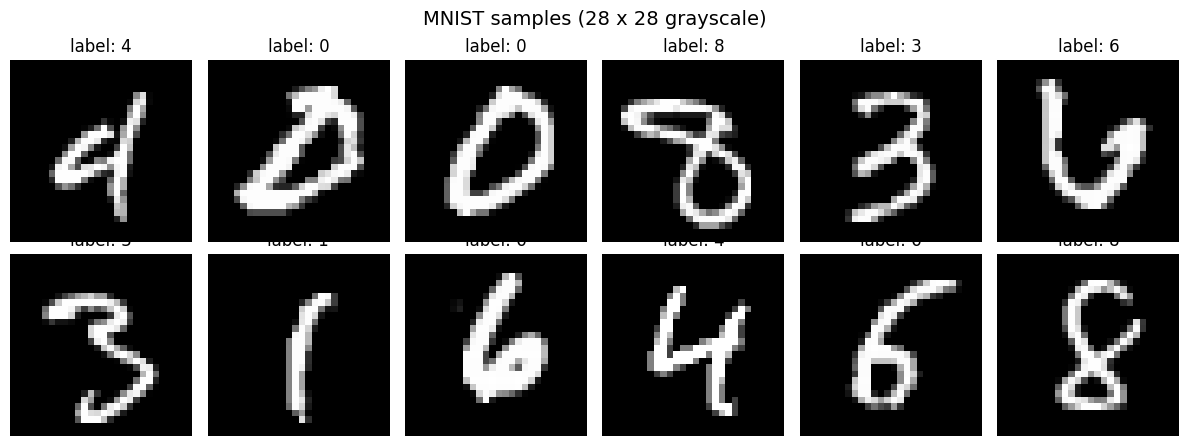

In [5]:
fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
fig.suptitle('MNIST samples (28 x 28 grayscale)', fontsize=14)

for ax in axes.flat:
    idx = np.random.randint(0, len(x_train))
    ax.imshow(x_train[idx, :, :, 0], cmap='gray')   # note the [..., 0] to drop the channel
    ax.set_title(f'label: {y_train[idx]}')
    ax.axis('off')

plt.tight_layout()
plt.show()

---
# Part B - What a convolution actually does

Before we let a network *learn* anything, let us do a convolution **by hand** with
numbers we choose ourselves. This is the single most important part of the lab: once you
see what a kernel does, the rest of the CNN is just bookkeeping.

---
## Step 6 - A kernel is a small grid of numbers

A **kernel** (also called a **filter**) is a tiny square of numbers - almost always 3x3
or 5x5. You slide it across the image, and at every position you:

1. line the kernel up with a patch of the image of the same size,
2. multiply each kernel number by the pixel underneath it,
3. add up all 9 products,
4. write that single number into the output.

That is the whole operation. Written out:

$$ \text{output}[i,j] \;=\; \sum_{u=0}^{2}\sum_{v=0}^{2} \text{image}[i+u,\; j+v] \times \text{kernel}[u,v] $$

The function below implements exactly that with two explicit loops. Real frameworks use
heavily optimised code, but the arithmetic is identical.

> **A note on naming:** strictly speaking, mathematical convolution flips the kernel
> before sliding. Every deep-learning framework skips the flip and implements
> *cross-correlation*, but calls it convolution anyway. Since the kernel is learned, the
> flip makes no practical difference - but it is worth knowing if you have met
> convolution in a signals course.

In [6]:
def convolve2d(image, kernel):
    # Slide `kernel` over `image` and return the output map. Pure NumPy, no shortcuts.
    kh, kw = kernel.shape
    ih, iw = image.shape

    out_h = ih - kh + 1          # <- this is where the shrinking comes from
    out_w = iw - kw + 1
    output = np.zeros((out_h, out_w))

    for i in range(out_h):
        for j in range(out_w):
            patch = image[i:i+kh, j:j+kw]        # the 3x3 window under the kernel
            output[i, j] = np.sum(patch * kernel) # multiply elementwise, then sum
    return output


# A tiny worked example so you can check the arithmetic by hand
tiny_image = np.array([[1, 2, 3, 0],
                       [4, 5, 6, 1],
                       [7, 8, 9, 2],
                       [0, 1, 2, 3]], dtype=float)

tiny_kernel = np.array([[1, 0, -1],
                        [1, 0, -1],
                        [1, 0, -1]], dtype=float)

print("image (4x4):\n", tiny_image)
print("\nkernel (3x3):\n", tiny_kernel)
print("\noutput (2x2):\n", convolve2d(tiny_image, tiny_kernel))

print("\nCheck the top-left output value by hand:")
patch = tiny_image[0:3, 0:3]
print("  patch under the kernel:\n", patch)
print("  patch * kernel:\n", patch * tiny_kernel)
print("  sum =", np.sum(patch * tiny_kernel))

image (4x4):
 [[1. 2. 3. 0.]
 [4. 5. 6. 1.]
 [7. 8. 9. 2.]
 [0. 1. 2. 3.]]

kernel (3x3):
 [[ 1.  0. -1.]
 [ 1.  0. -1.]
 [ 1.  0. -1.]]

output (2x2):
 [[-6. 12.]
 [-6.  8.]]

Check the top-left output value by hand:
  patch under the kernel:
 [[1. 2. 3.]
 [4. 5. 6.]
 [7. 8. 9.]]
  patch * kernel:
 [[ 1.  0. -3.]
 [ 4.  0. -6.]
 [ 7.  0. -9.]]
  sum = -6.0


### Why that kernel found vertical edges

The kernel we used was

```
 1  0  -1
 1  0  -1
 1  0  -1
```

Read it as an instruction: **"add up the left column, subtract the right column."**

- If the patch is uniform (all dark, or all bright), left and right cancel -> output ~ 0.
- If the patch is bright on the left and dark on the right -> large **positive** output.
- Dark on the left, bright on the right -> large **negative** output.

So this kernel is blind to flat regions and fires only where brightness changes
horizontally - that is, at a **vertical edge**. Rotate the numbers 90 degrees and you get
a horizontal edge detector.

**This is the key idea of a CNN.** A kernel is a small pattern detector, and because you
slide the *same* kernel everywhere, it detects that pattern **anywhere in the image**.
A stroke in the top-left and the same stroke in the bottom-right are found by the same
9 numbers.

---
## Step 7 - Hand-designed kernels on a real digit

Let us apply five classic hand-designed kernels to an actual MNIST digit and look at
what comes out.

Using a training image of the digit: 5


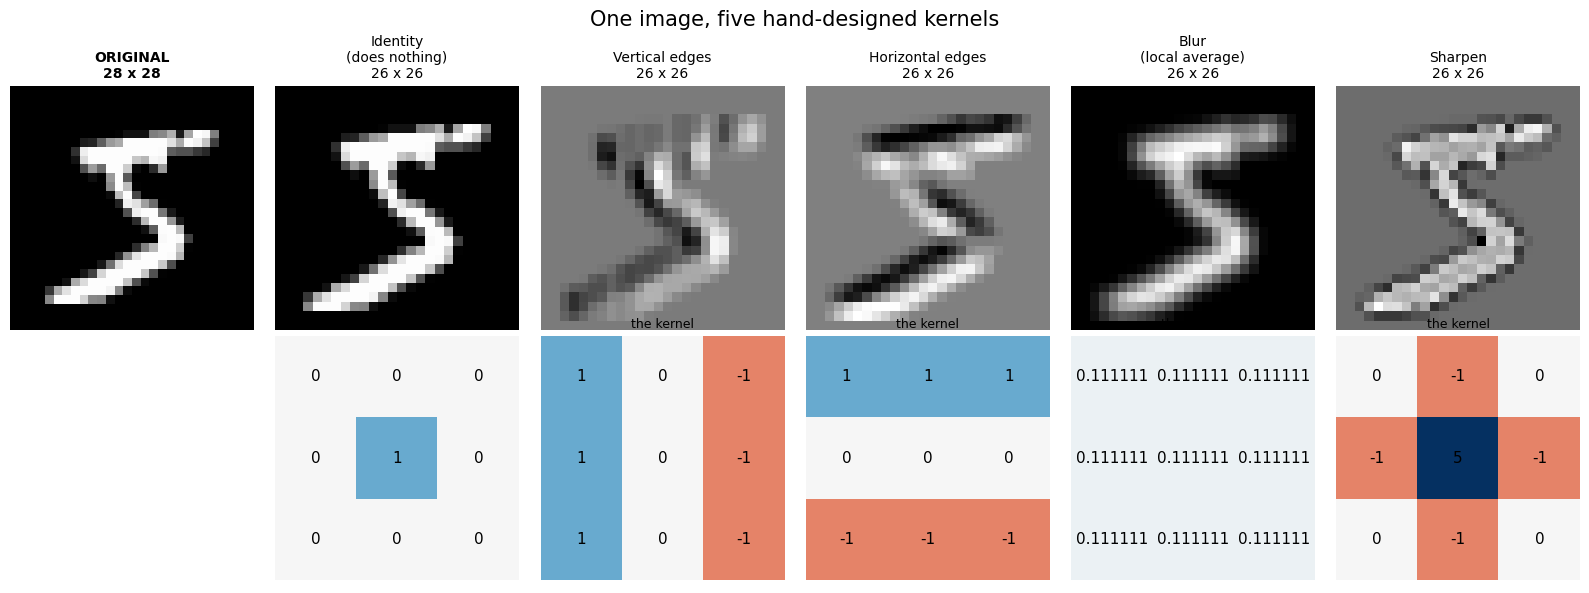

In [7]:
digit = x_train[0, :, :, 0]            # a real MNIST image, 28x28
print("Using a training image of the digit:", y_train[0])

kernels = {
    'Identity\n(does nothing)':      np.array([[0, 0, 0], [0, 1, 0], [0, 0, 0]], float),
    'Vertical edges':                np.array([[1, 0, -1], [1, 0, -1], [1, 0, -1]], float),
    'Horizontal edges':              np.array([[1, 1, 1], [0, 0, 0], [-1, -1, -1]], float),
    'Blur\n(local average)':         np.ones((3, 3)) / 9.0,
    'Sharpen':                       np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], float),
}

fig, axes = plt.subplots(2, 6, figsize=(16, 6))
fig.suptitle('One image, five hand-designed kernels', fontsize=15)

axes[0, 0].imshow(digit, cmap='gray')
axes[0, 0].set_title('ORIGINAL\n28 x 28', fontsize=10, weight='bold')
axes[0, 0].axis('off')
axes[1, 0].axis('off')

for col, (name, k) in enumerate(kernels.items(), start=1):
    result = convolve2d(digit, k)

    axes[0, col].imshow(result, cmap='gray')
    axes[0, col].set_title(f'{name}\n{result.shape[0]} x {result.shape[1]}', fontsize=10)
    axes[0, col].axis('off')

    # show the kernel numbers themselves underneath
    axes[1, col].imshow(k, cmap='RdBu', vmin=-2, vmax=2)
    for (r, c), v in np.ndenumerate(k):
        axes[1, col].text(c, r, f'{v:g}', ha='center', va='center', fontsize=11)
    axes[1, col].set_title('the kernel', fontsize=9)
    axes[1, col].axis('off')

plt.tight_layout()
plt.show()

### Why we see this

- **Identity** returns the digit unchanged - proof that the machinery itself does not
  distort anything. The only change is the size (see Step 8).
- **Vertical edges** lights up the left and right sides of strokes and goes dark in the
  middle of thick strokes. The flat black background vanishes completely.
- **Horizontal edges** does the same for the tops and bottoms of strokes. Compare the two:
  they highlight *different parts of the same digit*. One kernel is not enough - which is
  exactly why a Conv2D layer has many.
- **Blur** replaces each pixel with the average of its 9 neighbours, softening everything.
- **Sharpen** does the opposite, exaggerating differences from the neighbourhood.

**The crucial handover:** we *chose* these 45 numbers using human knowledge of image
processing. A CNN does **not** get told them. It starts with random numbers in every
kernel and *learns* useful ones by gradient descent - exactly the way the 784 weights in
Lab 01 were learned. The kernels are simply the weights of a Conv2D layer.

---
## Step 8 - Output shape: why 28 becomes 26 (OUTPUT SHAPE)

Notice every result above is **26 x 26**, not 28 x 28. Two pixels vanished from each side.

The reason: the 3x3 kernel must sit **entirely inside** the image. Centre it on the
corner pixel and it hangs off the edge, so the very outermost ring of pixels never gets
to be a centre. With a 3x3 kernel you lose 1 pixel from each of the four borders, so the
height and width each shrink by 2.

The general formula:

$$ \text{output size} \;=\; \left\lfloor \frac{\text{input} - \text{kernel} + 2 \times \text{padding}}{\text{stride}} \right\rfloor + 1 $$

For our case: `(28 - 3 + 0) / 1 + 1 = 26`.

**Two padding modes in Keras:**

| `padding=` | Behaviour | 28x28 with 3x3 gives |
|---|---|---|
| `'valid'` (default) | no padding, kernel stays fully inside | **26 x 26** (shrinks) |
| `'same'` | pad a ring of zeros around the border | **28 x 28** (preserved) |

We will use the default `'valid'` in this lab precisely *because* it shrinks - watching
the numbers change makes the mechanism visible. In real networks `'same'` is very common,
since it lets you stack many layers without running out of pixels.

In [8]:
def conv_output_size(n_in, k, padding=0, stride=1):
    return (n_in - k + 2*padding) // stride + 1

print(f"{'input':>7} {'kernel':>7} {'pad':>5} {'stride':>7} {'output':>7}")
print("-" * 38)
for n, k, p, s in [(28, 3, 0, 1),   # our conv1: valid padding
                   (28, 3, 1, 1),   # padding='same'
                   (28, 5, 0, 1),   # bigger kernel loses more
                   (28, 3, 0, 2),   # stride 2 halves the output
                   (13, 3, 0, 1),   # our conv2 input
                   ]:
    print(f"{n:>7} {k:>7} {p:>5} {s:>7} {conv_output_size(n,k,p,s):>7}")

print("\nAnd MaxPooling2D((2,2)) simply halves, discarding any odd leftover row/column:")
for n in [26, 13, 11, 5]:
    print(f"  {n:>3} -> {n//2:>3}")

  input  kernel   pad  stride  output
--------------------------------------
     28       3     0       1      26
     28       3     1       1      28
     28       5     0       1      24
     28       3     0       2      13
     13       3     0       1      11

And MaxPooling2D((2,2)) simply halves, discarding any odd leftover row/column:
   26 ->  13
   13 ->   6
   11 ->   5
    5 ->   2


---
# Part C - Building the CNN

---
## Step 9 - The Sequential model

`keras.Sequential` is the same "stack of layers in a straight line" container from
Lab 01. Only the layer types are new.

```python
layers.Input(shape=(28, 28, 1))        # one image: height, width, channels
layers.Conv2D(8, (3, 3), activation='relu')
layers.MaxPooling2D((2, 2))
layers.Conv2D(16, (3, 3), activation='relu')
layers.MaxPooling2D((2, 2))
layers.Flatten()
layers.Dense(10, activation='softmax')
```

**Reading `Conv2D(8, (3, 3))`:** *"apply 8 different 3x3 kernels."* The first number is
how many filters (and therefore how many output channels), the tuple is the kernel size.

**Why only 8 and 16 filters?** Real MNIST CNNs use 32 and 64. We use 8 and 16 so that
every feature map fits on one screen and can be looked at individually - the entire point
of this lab. Accuracy will still be excellent.

**`MaxPooling2D((2, 2))`** takes each non-overlapping 2x2 block and keeps only the largest
value, halving height and width. It has **no parameters** - nothing to learn. It exists to
shrink the data and to make the network slightly tolerant of a feature shifting by a pixel.

**`Flatten`** unrolls the final `(5, 5, 16)` block into a flat vector of
`5 x 5 x 16 = 400` numbers, so an ordinary `Dense` layer can finish the job.

**`Dense(10, activation='softmax')`** gives 10 outputs - one score per digit - and
**softmax** turns them into probabilities that sum to exactly 1. (In Lab 01 we had one
output and used sigmoid, because the question was yes/no. Here it is "which of 10?")

In [9]:
model = keras.Sequential([
    layers.Input(shape=(28, 28, 1), name='input'),

    layers.Conv2D(8,  (3, 3), activation='relu', name='conv1'),
    layers.MaxPooling2D((2, 2), name='pool1'),

    layers.Conv2D(16, (3, 3), activation='relu', name='conv2'),
    layers.MaxPooling2D((2, 2), name='pool2'),

    layers.Flatten(name='flatten'),
    layers.Dense(10, activation='softmax', name='output'),
], name='tiny_cnn')

model.summary()

Model: "tiny_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 26, 26, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 13, 13, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 11, 11, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         4,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,258 (20.54 KB)

 Trainable params: 5,258 (20.54 KB)

 Non-trainable params: 0 (0.00 B)

---
## Step 10 - Read the summary carefully: how the shape travels

The `Output Shape` column is the story of the whole network. The leading `None` is the
**batch dimension** - Keras writes `None` because the model works with any number of
images at once.

| Layer | Output shape | What changed | Why |
|---|---|---|---|
| input | `(28, 28, 1)` | - | one grayscale image |
| **conv1** | `(26, 26, 8)` | 28->26, 1->8 channels | 3x3 valid padding trims 2; **8 filters make 8 channels** |
| pool1 | `(13, 13, 8)` | 26->13 | 2x2 max pooling halves |
| **conv2** | `(11, 11, 16)` | 13->11, 8->16 channels | trims 2 again; 16 filters |
| pool2 | `(5, 5, 16)` | 11->5 | halves, 11//2 = 5 (the odd row is dropped) |
| flatten | `(400,)` | grid -> list | 5 x 5 x 16 = 400 |
| output | `(10,)` | 400 -> 10 | one probability per digit |

**Two things shrink and one thing grows.** Height and width go down (28 -> 26 -> 13 ->
11 -> 5) while the number of channels goes up (1 -> 8 -> 16). This is the classic CNN
shape: trade *spatial* detail for *feature* variety. Early layers say "where is the ink";
later layers say "what kind of shape is here".

Run the cell below to see the shapes computed from first principles rather than read off
the summary.

In [10]:
print("Tracing the shape through the network by hand:\n")
h = w = 28; c = 1
print(f"  input                  -> ({h}, {w}, {c})")

h, w, c = h-2, w-2, 8;      print(f"  Conv2D(8,  3x3, valid) -> ({h}, {w}, {c})    28-3+1 = 26, channels = n_filters")
h, w    = h//2, w//2;       print(f"  MaxPooling2D(2x2)      -> ({h}, {w}, {c})    26/2 = 13, channels unchanged")
h, w, c = h-2, w-2, 16;     print(f"  Conv2D(16, 3x3, valid) -> ({h}, {w}, {c})    13-3+1 = 11, channels = n_filters")
h, w    = h//2, w//2;       print(f"  MaxPooling2D(2x2)      -> ({h}, {w}, {c})      11//2 = 5, one row/col discarded")
print(f"  Flatten                -> ({h*w*c},)          {h} x {w} x {c} = {h*w*c}")
print(f"  Dense(10)              -> (10,)")

print("\nCompare with what Keras reports:")
for layer in model.layers:
    print(f"  {layer.name:<8} {str(layer.output.shape):<20} params: {layer.count_params():>6,}")

Tracing the shape through the network by hand:

  input                  -> (28, 28, 1)
  Conv2D(8,  3x3, valid) -> (26, 26, 8)    28-3+1 = 26, channels = n_filters
  MaxPooling2D(2x2)      -> (13, 13, 8)    26/2 = 13, channels unchanged
  Conv2D(16, 3x3, valid) -> (11, 11, 16)    13-3+1 = 11, channels = n_filters
  MaxPooling2D(2x2)      -> (5, 5, 16)      11//2 = 5, one row/col discarded
  Flatten                -> (400,)          5 x 5 x 16 = 400
  Dense(10)              -> (10,)

Compare with what Keras reports:
  conv1    (None, 26, 26, 8)    params:     80
  pool1    (None, 13, 13, 8)    params:      0
  conv2    (None, 11, 11, 16)   params:  1,168
  pool2    (None, 5, 5, 16)     params:      0
  flatten  (None, 400)          params:      0
  output   (None, 10)           params:  4,010


---
## Step 11 - CHANNELS: the part everyone gets wrong

Look at the parameter counts. `conv1` has **80** and `conv2` has **1,168**. Where do
those numbers come from?

### conv1: 8 filters, each 3x3, over a 1-channel input

Each kernel is `3 x 3 x 1 = 9` weights, plus 1 bias:

```
8 filters x (3 x 3 x 1 weights + 1 bias) = 8 x 10 = 80   OK
```

### conv2: 16 filters, each 3x3, over an **8-channel** input

Here is the trap. A conv2 filter is **not** 3x3 = 9 numbers. Its input has 8 channels, and
**every filter must look at all of them at once**. So each filter is a 3x3x8 *cube* of
weights - it reads a 3x3 window from all 8 incoming feature maps simultaneously and
produces **one** output number.

```
16 filters x (3 x 3 x 8 weights + 1 bias) = 16 x 73 = 1,168   OK
```

### The rule

$$ \text{params} = n_{\text{filters}} \times (k_h \times k_w \times C_{\text{in}} + 1) $$

**Say it out loud:** *a filter's depth is always the number of input channels; the number
of filters becomes the number of output channels.*

That is why the diagram of a CNN shows blocks getting deeper: each layer's depth is
decided by how many filters *you* asked for, and each filter silently spans the full depth
of whatever came before it.

In [11]:
def conv_params(n_filters, k, c_in):
    return n_filters * (k*k*c_in + 1)

print("conv1: 8 filters, 3x3 kernel, 1 input channel")
print(f"   each filter = 3 x 3 x 1 = {3*3*1} weights + 1 bias = {3*3*1+1}")
print(f"   total = 8 x {3*3*1+1} = {conv_params(8,3,1)}")
print(f"   Keras says: {model.get_layer('conv1').count_params()}\n")

print("conv2: 16 filters, 3x3 kernel, 8 input channels")
print(f"   each filter = 3 x 3 x 8 = {3*3*8} weights + 1 bias = {3*3*8+1}")
print(f"   total = 16 x {3*3*8+1} = {conv_params(16,3,8)}")
print(f"   Keras says: {model.get_layer('conv2').count_params()}\n")

# Confirm the actual stored shapes
w1, b1 = model.get_layer('conv1').get_weights()
w2, b2 = model.get_layer('conv2').get_weights()
print("Stored weight tensors  (kernel_h, kernel_w, channels_in, channels_out):")
print("   conv1 kernels:", w1.shape, " biases:", b1.shape)
print("   conv2 kernels:", w2.shape, " biases:", b2.shape)
print("\nNotice conv2's third dimension is 8 - it matches conv1's output channels.")

conv1: 8 filters, 3x3 kernel, 1 input channel
   each filter = 3 x 3 x 1 = 9 weights + 1 bias = 10
   total = 8 x 10 = 80
   Keras says: 80

conv2: 16 filters, 3x3 kernel, 8 input channels
   each filter = 3 x 3 x 8 = 72 weights + 1 bias = 73
   total = 16 x 73 = 1168
   Keras says: 1168

Stored weight tensors  (kernel_h, kernel_w, channels_in, channels_out):
   conv1 kernels: (3, 3, 1, 8)  biases: (8,)
   conv2 kernels: (3, 3, 8, 16)  biases: (16,)

Notice conv2's third dimension is 8 - it matches conv1's output channels.


---
## Step 12 - Parameter sharing: why a CNN is so much smaller

Our whole CNN has about 5,000 parameters. Ask what a Dense layer would need to do
something comparable.

A `Dense` layer connecting 784 input pixels to 26x26x8 = 5,408 outputs would need
`784 x 5408 + 5408 = 4.25 million` weights. Our conv1 does the analogous job with **80**.

The saving comes from **parameter sharing**: the same 9 numbers are reused at every one
of the 676 positions in the image. A Dense layer would learn a separate weight for every
(input pixel, output unit) pair, which means learning "what a vertical stroke looks like"
separately for the top-left corner, the middle, the bottom-right, and everywhere else.

This buys two things:

1. **Far fewer parameters** -> less data needed, less overfitting, faster training.
2. **Translation equivariance** -> a feature learned anywhere is detected everywhere.

In [12]:
dense_equivalent = 784 * (26*26*8) + (26*26*8)
conv_actual      = model.get_layer('conv1').count_params()

print(f"Dense layer 784 -> 5,408 outputs : {dense_equivalent:>12,} parameters")
print(f"Conv2D(8, 3x3)  -> same 5,408    : {conv_actual:>12,} parameters")
print(f"Reduction factor                 : {dense_equivalent/conv_actual:>12,.0f} x")

print(f"\nWhole CNN: {model.count_params():,} parameters")
print("Each conv1 kernel is applied at 26 x 26 =", 26*26, "positions,")
print("but there are still only 9 weights in it - reused every time.")

Dense layer 784 -> 5,408 outputs :    4,245,280 parameters
Conv2D(8, 3x3)  -> same 5,408    :           80 parameters
Reduction factor                 :       53,066 x

Whole CNN: 5,258 parameters
Each conv1 kernel is applied at 26 x 26 = 676 positions,
but there are still only 9 weights in it - reused every time.


---
# Part D - Training

---
## Step 13 - Compile

- **`optimizer='adam'`** - the algorithm that adjusts every weight, including all the
  kernel values.
- **`loss='sparse_categorical_crossentropy'`** - the 10-class version of the loss from
  Lab 01. "Sparse" means our labels are integers `0..9` rather than one-hot vectors.
- **`metrics=['accuracy']`** - the human-readable score.

In [13]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

print("Model compiled.")
print("Loss     : sparse_categorical_crossentropy  (labels are integers 0-9)")
print("Optimizer: adam")

Model compiled.
Loss     : sparse_categorical_crossentropy  (labels are integers 0-9)
Optimizer: adam


---
## Step 14 - What does the network do BEFORE training?

Every kernel currently holds small random numbers. Let us establish the baseline.

> **Look for:** accuracy around **10%**. With 10 equally likely classes, random guessing
> is 1 in 10. The network knows nothing yet.

In [14]:
loss_before, acc_before = model.evaluate(x_test, y_test, verbose=0)
print(f"BEFORE training -> accuracy: {acc_before*100:5.2f}%   loss: {loss_before:.4f}")
print(f"Random guessing with 10 classes would be about 10.00%")

probs_before = model.predict(x_test[:1], verbose=0)[0]
print(f"\nPredicted probabilities for one test image (true label {y_test[0]}):")
for d, p in enumerate(probs_before):
    print(f"   digit {d}: {p:.4f}  {'#' * int(p*60)}")
print(f"\nThey sum to {probs_before.sum():.4f} - softmax always guarantees exactly 1.")

BEFORE training -> accuracy: 10.04%   loss: 2.3428
Random guessing with 10 classes would be about 10.00%

Predicted probabilities for one test image (true label 7):
   digit 0: 0.1411  ########
   digit 1: 0.1102  ######
   digit 2: 0.0955  #####
   digit 3: 0.0827  ####
   digit 4: 0.0902  #####
   digit 5: 0.1120  ######
   digit 6: 0.0890  #####
   digit 7: 0.0833  #####
   digit 8: 0.1088  ######
   digit 9: 0.0872  #####

They sum to 1.0000 - softmax always guarantees exactly 1.


### Save the untrained kernels

We will compare these against the trained ones later, so keep a copy now.

In [15]:
kernels_before = model.get_layer('conv1').get_weights()[0].copy()   # (3, 3, 1, 8)
print("Saved untrained conv1 kernels, shape:", kernels_before.shape)
print("\nFilter 0 before training:\n", kernels_before[:, :, 0, 0].round(3))
print("\nJust random numbers - no pattern.")

Saved untrained conv1 kernels, shape: (3, 3, 1, 8)

Filter 0 before training:
 [[ 0.195  0.013 -0.262]
 [ 0.196 -0.212 -0.249]
 [-0.205 -0.037 -0.1  ]]

Just random numbers - no pattern.


---
## Step 15 - Train

Five passes over the training set, with 20% held back for validation.

> **Look for:** accuracy should exceed 95% within the first epoch. A CNN learns MNIST
> very quickly - the architecture matches the problem far better than a flat Dense net.

*This takes roughly 2-3 minutes on CPU.*

In [16]:
history = model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2,
    verbose=2          # one line per epoch
)
print("\nTraining complete.")

Epoch 1/5


750/750 - 3s - 4ms/step - accuracy: 0.8896 - loss: 0.3904 - val_accuracy: 0.9658 - val_loss: 0.1186


Epoch 2/5


750/750 - 3s - 4ms/step - accuracy: 0.9674 - loss: 0.1072 - val_accuracy: 0.9761 - val_loss: 0.0841


Epoch 3/5


750/750 - 3s - 4ms/step - accuracy: 0.9751 - loss: 0.0818 - val_accuracy: 0.9791 - val_loss: 0.0717


Epoch 4/5


750/750 - 3s - 4ms/step - accuracy: 0.9788 - loss: 0.0693 - val_accuracy: 0.9799 - val_loss: 0.0663


Epoch 5/5


750/750 - 3s - 4ms/step - accuracy: 0.9808 - loss: 0.0612 - val_accuracy: 0.9807 - val_loss: 0.0631



Training complete.


---
## Step 16 - Training curves

`model.fit` returns a `history` object holding loss and accuracy for every epoch.

> **Look for:** validation accuracy tracking training accuracy closely. If the two
> separate - training still climbing while validation flattens or falls - the model is
> memorising rather than generalising.

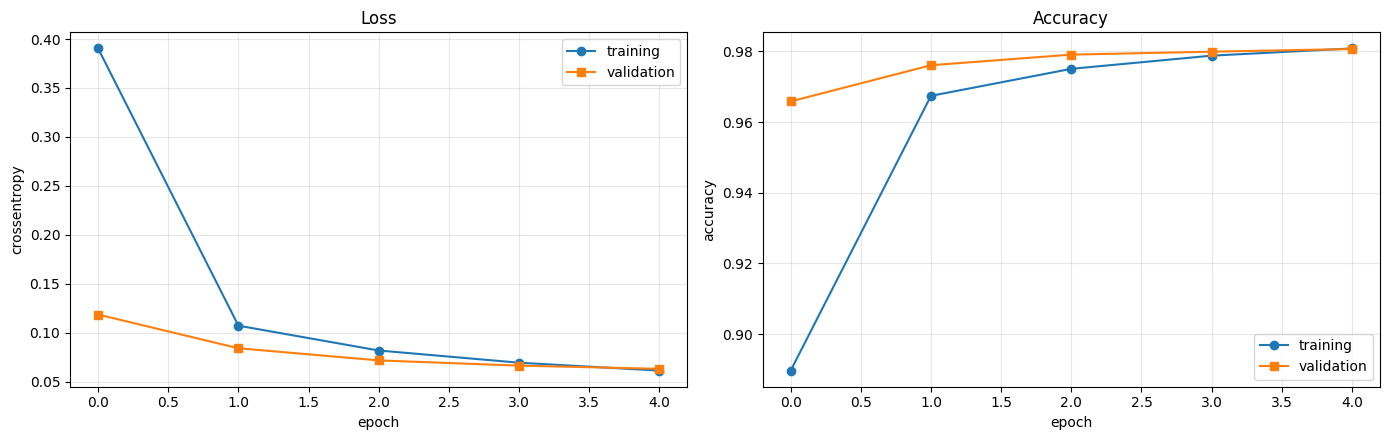

Final training accuracy  : 0.9808
Final validation accuracy: 0.9807


In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

ax1.plot(history.history['loss'],     'o-', label='training')
ax1.plot(history.history['val_loss'], 's-', label='validation')
ax1.set_title('Loss'); ax1.set_xlabel('epoch'); ax1.set_ylabel('crossentropy')
ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(history.history['accuracy'],     'o-', label='training')
ax2.plot(history.history['val_accuracy'], 's-', label='validation')
ax2.set_title('Accuracy'); ax2.set_xlabel('epoch'); ax2.set_ylabel('accuracy')
ax2.legend(); ax2.grid(alpha=0.3)

plt.tight_layout(); plt.show()

print(f"Final training accuracy  : {history.history['accuracy'][-1]:.4f}")
print(f"Final validation accuracy: {history.history['val_accuracy'][-1]:.4f}")

---
## Step 17 - Test the trained model

The honest score, on 10,000 images the network has never seen.

In [18]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)

print(f"BEFORE training -> {acc_before*100:5.2f}%")
print(f"AFTER  training -> {test_acc*100:5.2f}%")
print(f"Test loss: {test_loss:.4f}")
print(f"\nAchieved with only {model.count_params():,} parameters.")

# Which digits does it still confuse?
pred_classes = np.argmax(model.predict(x_test, verbose=0), axis=1)
wrong = np.where(pred_classes != y_test)[0]
print(f"\nMistakes: {len(wrong)} out of {len(y_test)}")

digits, counts = np.unique(y_test[wrong], return_counts=True)
print("Errors per true digit:")
for d, c in sorted(zip(digits, counts), key=lambda t: -t[1]):
    print(f"   digit {d}: {c:>3} {'#' * c}")

BEFORE training -> 10.04%
AFTER  training -> 98.26%
Test loss: 0.0557

Achieved with only 5,258 parameters.



Mistakes: 174 out of 10000
Errors per true digit:
   digit 9:  34 ##################################
   digit 6:  24 ########################
   digit 8:  23 #######################
   digit 2:  20 ####################
   digit 5:  20 ####################
   digit 7:  19 ###################
   digit 3:  18 ##################
   digit 4:   9 #########
   digit 1:   5 #####
   digit 0:   2 ##


---
# Part E - Looking inside every layer

This is what the lab was built for. We will push **one** image through the network and
plot **every intermediate result**, layer by layer, then explain what we are looking at.

---
## Step 18 - Extracting the activations

A Keras layer is just a callable object. So the simplest and most reliable way to see
inside the model is to call the layers **one at a time** and keep every intermediate
result:

```python
x = image
for layer in model.layers:
    x = layer(x)        # the output of one layer is the input to the next
    save(x)
```

That loop *is* the model. There is no hidden machinery - `model.predict` does exactly
this and only returns the last value.

> *(An alternative you will see in books is building a second `keras.Model` whose outputs
> are the intermediate layers. It gives the same numbers; the loop below is easier to read
> and never runs into graph-construction quirks.)*

In [19]:
def get_all_activations(model, image_batch):
    # Run one batch through the model, keeping every layer's output.
    acts = {}
    x = tf.convert_to_tensor(image_batch)
    for layer in model.layers:
        x = layer(x)
        acts[layer.name] = np.array(x)
    return acts


SAMPLE = 0                                   # <-- change this to explore other digits
sample_image = x_test[SAMPLE:SAMPLE+1]       # slice keeps the batch dimension: (1,28,28,1)
sample_label = y_test[SAMPLE]

activations = get_all_activations(model, sample_image)

print(f"Input image is the digit: {sample_label}\n")
print(f"{'layer':<10} {'output shape':<22} {'meaning'}")
print("-" * 68)
print(f"{'(input)':<10} {str(sample_image.shape):<22} 1 image, 28x28, 1 channel")
meanings = {
    'conv1'  : '8 feature maps of 26x26',
    'pool1'  : 'same 8 maps, halved to 13x13',
    'conv2'  : '16 feature maps of 11x11',
    'pool2'  : 'same 16 maps, halved to 5x5',
    'flatten': '5 x 5 x 16 unrolled into a vector',
    'output' : '10 class probabilities',
}
for name, a in activations.items():
    print(f"{name:<10} {str(a.shape):<22} {meanings[name]}")

Input image is the digit: 7

layer      output shape           meaning
--------------------------------------------------------------------
(input)    (1, 28, 28, 1)         1 image, 28x28, 1 channel
conv1      (1, 26, 26, 8)         8 feature maps of 26x26
pool1      (1, 13, 13, 8)         same 8 maps, halved to 13x13
conv2      (1, 11, 11, 16)        16 feature maps of 11x11
pool2      (1, 5, 5, 16)          same 16 maps, halved to 5x5
flatten    (1, 400)               5 x 5 x 16 unrolled into a vector
output     (1, 10)                10 class probabilities


---
## Step 19 - The input

The starting point: one 28x28 grayscale image. Everything below is derived from these
784 numbers.

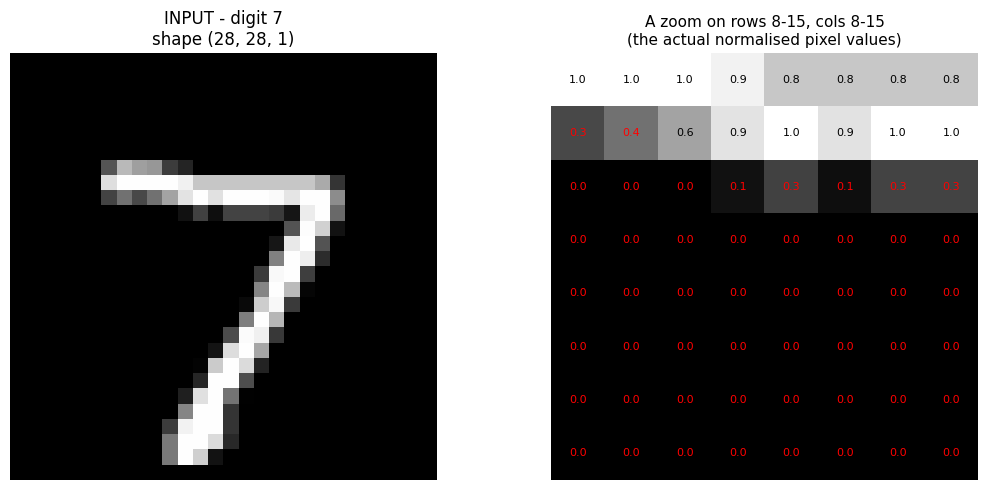

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5))

ax1.imshow(sample_image[0, :, :, 0], cmap='gray')
ax1.set_title(f'INPUT - digit {sample_label}\nshape (28, 28, 1)', fontsize=12)
ax1.axis('off')

# The same image with the actual numbers printed on a zoomed-in patch
patch = sample_image[0, 8:16, 8:16, 0]
ax2.imshow(patch, cmap='gray')
for (r, c), v in np.ndenumerate(patch):
    ax2.text(c, r, f'{v:.1f}', ha='center', va='center',
             color='red' if v < 0.5 else 'black', fontsize=8)
ax2.set_title('A zoom on rows 8-15, cols 8-15\n(the actual normalised pixel values)', fontsize=11)
ax2.axis('off')

plt.tight_layout(); plt.show()

---
## Step 20 - conv1: the 8 feature maps

Eight kernels slid across the image, each producing its own 26x26 output. Those eight
outputs stacked together are the `(26, 26, 8)` tensor.

**What you are looking at:** each panel is one filter's answer to the question
*"where in this image does my pattern appear?"* Bright (yellow) = strong response,
dark (purple) = no response.

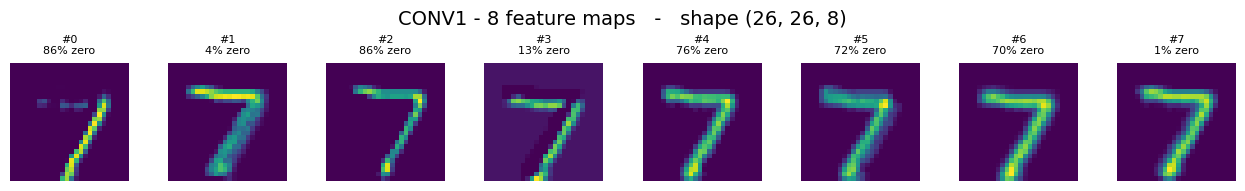

In [21]:
def plot_feature_maps(maps, title, ncols=8, cmap='viridis'):
    # maps has shape (height, width, n_channels)
    n = maps.shape[-1]
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(1.6*ncols, 1.9*nrows))
    axes = np.atleast_2d(axes).reshape(nrows, ncols)

    for i in range(nrows * ncols):
        ax = axes[i // ncols, i % ncols]
        if i < n:
            ax.imshow(maps[:, :, i], cmap=cmap)
            pct_zero = 100.0 * np.mean(maps[:, :, i] == 0)
            ax.set_title(f'#{i}\n{pct_zero:.0f}% zero', fontsize=8)
        ax.axis('off')

    fig.suptitle(f'{title}   -   shape {maps.shape}', fontsize=14)
    plt.tight_layout()
    plt.show()


plot_feature_maps(activations['conv1'][0], 'CONV1 - 8 feature maps', ncols=8)

### Why we see this

**Each map highlights a different aspect of the same digit.** Compare the panels: one
picks out left-hand edges, another the top edges of strokes, another responds to the
stroke interiors. The network was never told to do this - it discovered that edge-like
detectors are the most useful first step, exactly as human-designed image processing
concluded decades ago.

**The background is uniformly dark everywhere.** Flat black regions give a weighted sum
near zero, and ReLU clips anything negative to exactly 0. Only where the image *changes*
does a filter respond.

**Look at the "% zero" figures - and notice how wildly they differ.** ReLU
(`max(x, 0)`) clips every negative response to exactly zero. In a typical run some
filters come out around 1-15% zero while others reach 75-90%. That spread is the
interesting part: a filter that is 85% zero is **highly selective**, firing only on a
specific stroke orientation, while one that is 2% zero is responding almost everywhere
and acts more like a general brightness or blur detector. Both kinds are useful, and the
network arrived at the mix on its own.

**Sparsity is a feature, not a bug.** A mostly-zero map is a decisive statement about
where the pattern is *absent*.

> **A caution about "dead filters":** textbooks warn that a filter can get stuck
> outputting zero for every input, and it then stops learning (zero output gives zero
> gradient). In this small network trained on MNIST you will usually find that **all 8
> filters are alive** - check by re-running Step 26 with different `FILTER` values. Do not
> mistake a highly selective filter, dark for this particular digit, for a dead one.

**The maps are 26x26, not 28x28** - the two-pixel border loss from Step 8, visible here
as a slightly tighter crop.

---
## Step 21 - pool1: the same 8 maps, half the size

MaxPooling2D takes every non-overlapping 2x2 block and keeps only the maximum.
26x26 becomes 13x13. **The number of channels does not change** - pooling never mixes
channels, it only shrinks each one independently.

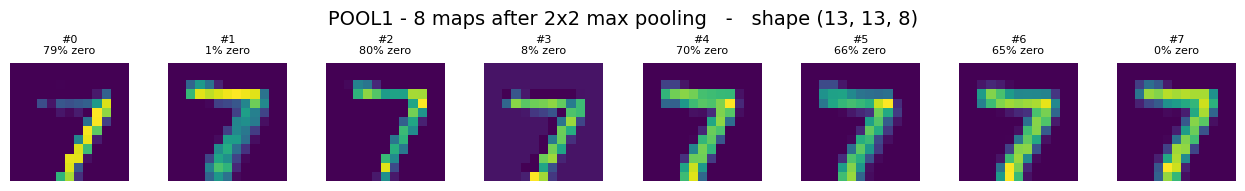

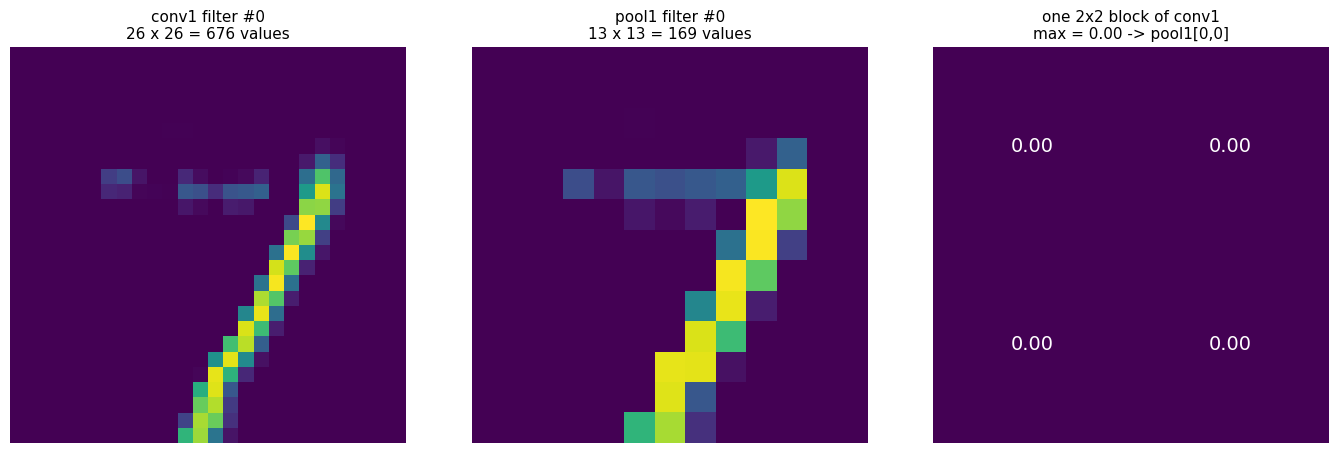

pool1[0,0,0] from the model = 0.0000
max of that 2x2 block         = 0.0000   <- they match


In [22]:
plot_feature_maps(activations['pool1'][0], 'POOL1 - 8 maps after 2x2 max pooling', ncols=8)

# Side by side for one filter so the effect is unmistakable
f = 0
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
axes[0].imshow(activations['conv1'][0, :, :, f], cmap='viridis')
axes[0].set_title(f'conv1 filter #{f}\n26 x 26 = {26*26} values', fontsize=11)
axes[1].imshow(activations['pool1'][0, :, :, f], cmap='viridis')
axes[1].set_title(f'pool1 filter #{f}\n13 x 13 = {13*13} values', fontsize=11)

# Show the actual max operation on one 2x2 block
block = activations['conv1'][0, 0:2, 0:2, f]
axes[2].imshow(block, cmap='viridis')
for (r, c), v in np.ndenumerate(block):
    axes[2].text(c, r, f'{v:.2f}', ha='center', va='center', color='white', fontsize=14)
axes[2].set_title(f'one 2x2 block of conv1\nmax = {block.max():.2f} -> pool1[0,0]', fontsize=11)

for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

print(f"pool1[0,0,{f}] from the model = {activations['pool1'][0,0,0,f]:.4f}")
print(f"max of that 2x2 block         = {block.max():.4f}   <- they match")

### Why we see this

**The pattern survives, the resolution does not.** Each pooled map is a blockier,
coarser version of the same picture. Three-quarters of the numbers were thrown away
(4 -> 1) yet the structure is still recognisable - which is the justification for doing it.

**Why keep the maximum rather than the average?** The feature map answers "how strongly
is my pattern here?". Within a small 2x2 neighbourhood we care that the pattern was found
*somewhere*, not exactly where. Taking the max preserves the strongest evidence;
averaging would dilute a sharp detection with three surrounding zeros.

**Two real benefits:**

1. **Less computation downstream.** conv2 now works on 13x13 instead of 26x26 - a quarter
   of the positions.
2. **Small-shift tolerance.** Nudge the digit one pixel right and the max over a 2x2 block
   very often stays the same, so the pooled map barely changes.

**MaxPooling has zero parameters.** Check `model.summary()` - the pooling rows read 0.
It is a fixed rule, not something learned.

---
## Step 22 - conv2: 16 feature maps, and where they come from

Now the important structural point from Step 11 made visible.

conv2 has **16 filters**, so we get 16 maps. But each of those filters is a
**3 x 3 x 8 cube** - it reads a 3x3 window from *all eight* pool1 maps at once and
combines them into a single number.

So each of the 16 panels below is **not** a transformation of one earlier map. It is a
*learned mixture* of all eight. That is how a CNN builds complexity: layer 1 finds edges,
layer 2 finds combinations of edges.

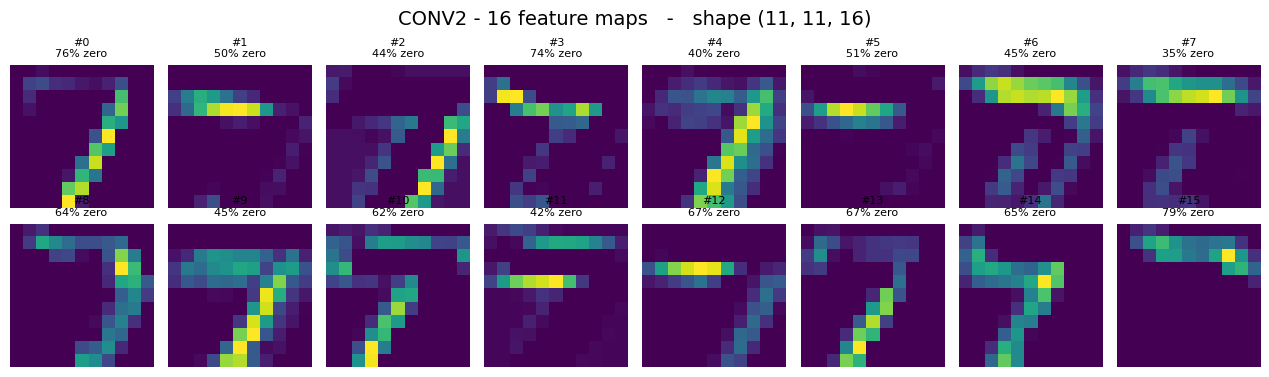

Where each conv2 map comes from:
  input to conv2 : pool1, shape (13, 13, 8)
  one conv2 filter: (3, 3, 8)  <- 3x3 across ALL 8 input channels
  16 such filters -> output (11, 11, 16)


In [23]:
plot_feature_maps(activations['conv2'][0], 'CONV2 - 16 feature maps', ncols=8)

print("Where each conv2 map comes from:")
print("  input to conv2 : pool1, shape", activations['pool1'].shape[1:])
print("  one conv2 filter:", model.get_layer('conv2').get_weights()[0][:, :, :, 0].shape,
      " <- 3x3 across ALL 8 input channels")
print("  16 such filters -> output", activations['conv2'].shape[1:])

### Why we see this

**They are much harder to interpret than conv1 - and that is the expected result.**
conv1 maps still look like the digit with an effect applied. conv2 maps look like
scattered blobs. Nobody can point at panel #7 and say "that detects the loop of a 9".
This is normal and worth stating plainly to students: **only the first layer is reliably
human-readable.** Depth buys abstraction, and abstraction costs interpretability.

**They are small - 11x11.** At this size each single cell already summarises a sizeable
patch of the original image. This is the **receptive field** growing: a conv1 cell sees a
3x3 patch of the input; a conv2 cell (after pooling) sees roughly an 8x8 patch. Deeper
cells see more context but fewer of them exist.

**They are very sparse.** Check the "% zero" labels - conv2 maps are typically emptier
than conv1. Later layers are looking for more specific things, which are present in fewer
places.

**The maps differ a lot in how busy they are** - typically from about 35% zero for the
most active up to 80% for the quietest. Try changing `SAMPLE` in Step 18 and re-running:
a filter that is nearly silent on a `7` often becomes one of the busiest on a `0`. They
are *selective*, not broken.

---
## Step 23 - pool2, flatten, and the final answer

The last three steps of the journey:

- **pool2** halves 11x11 to 5x5 (the odd 11th row and column are simply discarded).
- **flatten** unrolls the `(5, 5, 16)` block into a plain vector of 400 numbers.
  This is the moment the grid structure is finally abandoned - and it is deliberately
  placed at the *end*, after the convolutions have already used it.
- **output** is a Dense layer mapping those 400 numbers to 10 probabilities via softmax.

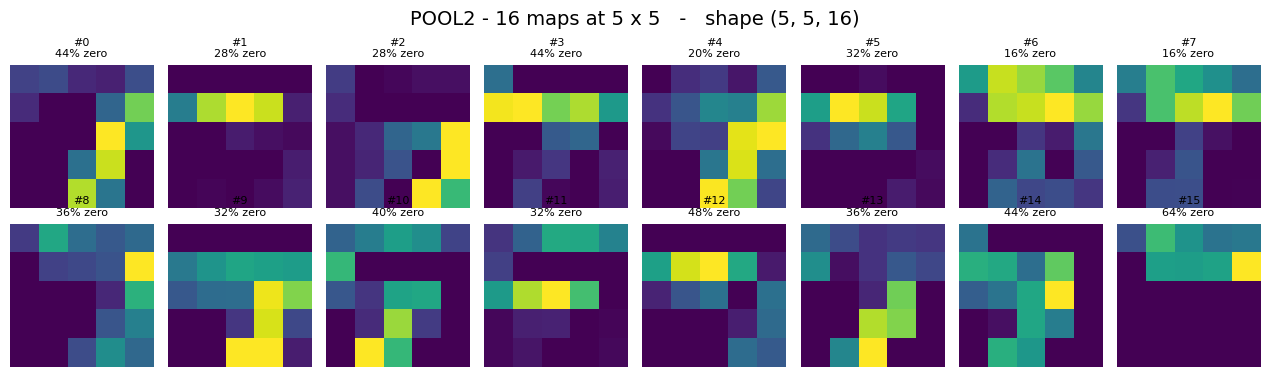

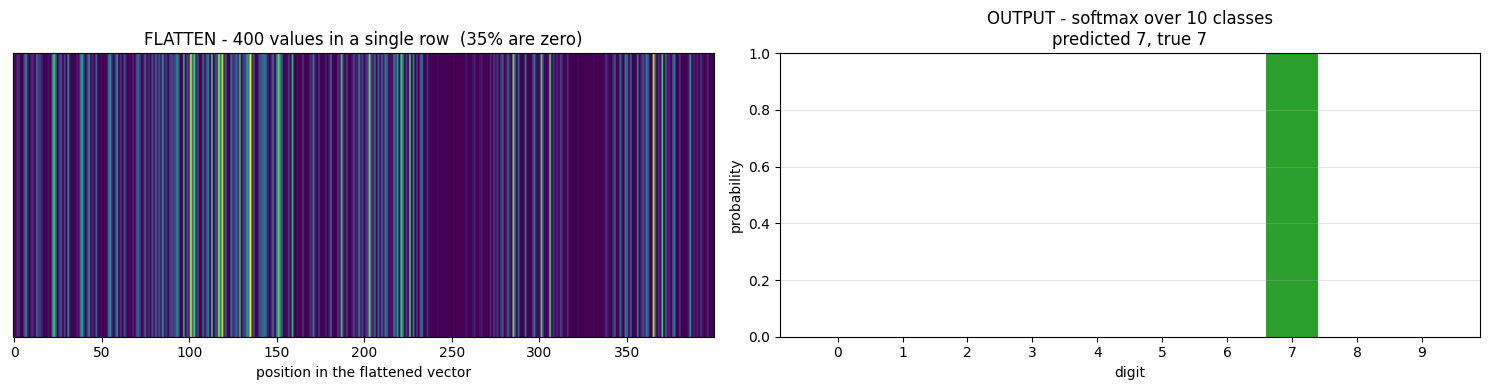

Probabilities sum to 1.000000
Most confident: digit 7 at 100.00%

Full distribution:
   0: 0.000000 
   1: 0.000000 
   2: 0.000002 
   3: 0.000004 
   4: 0.000000 
   5: 0.000000 
   6: 0.000000 
   7: 0.999994 #################################################
   8: 0.000000 
   9: 0.000000 


In [24]:
plot_feature_maps(activations['pool2'][0], 'POOL2 - 16 maps at 5 x 5', ncols=8)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4))

# Flatten shown as a 1-D strip
flat = activations['flatten'][0]
ax1.imshow(flat.reshape(1, -1), cmap='viridis', aspect='auto')
ax1.set_title(f'FLATTEN - {flat.shape[0]} values in a single row  '
              f'({np.mean(flat==0)*100:.0f}% are zero)', fontsize=12)
ax1.set_yticks([]); ax1.set_xlabel('position in the flattened vector')

# Final probabilities
probs = activations['output'][0]
colors = ['tab:green' if d == np.argmax(probs) else 'tab:blue' for d in range(10)]
ax2.bar(range(10), probs, color=colors)
ax2.set_xticks(range(10))
ax2.set_xlabel('digit'); ax2.set_ylabel('probability'); ax2.set_ylim(0, 1)
ax2.set_title(f'OUTPUT - softmax over 10 classes\n'
              f'predicted {np.argmax(probs)}, true {sample_label}', fontsize=12)
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout(); plt.show()

print(f"Probabilities sum to {probs.sum():.6f}")
print(f"Most confident: digit {np.argmax(probs)} at {probs.max()*100:.2f}%")
print("\nFull distribution:")
for d, p in enumerate(probs):
    bar = '#' * int(p * 50)
    print(f"   {d}: {p:.6f} {bar}")

### Why we see this

**The flatten strip is patchy, not uniform.** Roughly a third of the 400 values are
exactly zero, inherited from the ReLUs upstream, and the rest vary in strength. The
digit's identity is carried by *which* positions are active and how strongly - a compact
code that the final Dense layer reads off. The printed percentage above the strip tells
you the exact figure for this image.

**Softmax produces a near-one-hot answer.** One bar is close to 1.0 and the rest are
nearly invisible. Softmax exponentiates the scores before normalising, so a modest lead
in the raw score becomes a huge lead in probability. Compare with the flat, uncertain
distribution you saw before training in Step 14.

**Read the runner-up bar.** Even when correct, the second-highest bar tells you what the
network considered plausible - often a genuinely similar digit (4 and 9, 3 and 8,
5 and 6). That is a more informative error analysis than accuracy alone.

---
## Step 24 - The whole journey in one figure

Everything above, on a single row, so the shrinking-and-deepening pattern is visible at a
glance. For layers with many channels we show the **average across channels**, which
gives a rough sense of "where is this layer paying attention".

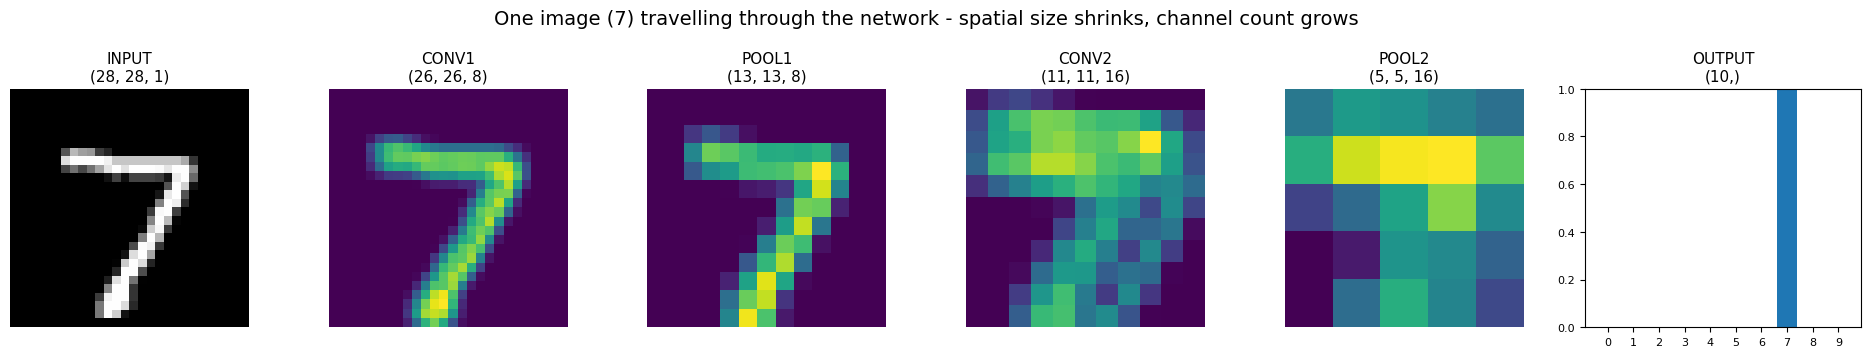

Spatial size : 28 -> 26 -> 13 -> 11 -> 5   (shrinking)
Channels     :  1 ->  8 ->  8 -> 16 -> 16  (growing)
Values total : 784 -> 5408 -> 1352 -> 1936 -> 400 -> 10


In [25]:
stages = [
    ('INPUT',   sample_image[0, :, :, 0],                       '(28, 28, 1)'),
    ('CONV1',   activations['conv1'][0].mean(axis=-1),          '(26, 26, 8)'),
    ('POOL1',   activations['pool1'][0].mean(axis=-1),          '(13, 13, 8)'),
    ('CONV2',   activations['conv2'][0].mean(axis=-1),          '(11, 11, 16)'),
    ('POOL2',   activations['pool2'][0].mean(axis=-1),          '(5, 5, 16)'),
]

fig, axes = plt.subplots(1, 6, figsize=(19, 3.6))
fig.suptitle(f'One image ({sample_label}) travelling through the network - '
             f'spatial size shrinks, channel count grows', fontsize=14)

for ax, (name, img, shape) in zip(axes, stages):
    ax.imshow(img, cmap='gray' if name == 'INPUT' else 'viridis')
    ax.set_title(f'{name}\n{shape}', fontsize=11)
    ax.axis('off')

axes[5].bar(range(10), activations['output'][0], color='tab:blue')
axes[5].set_title('OUTPUT\n(10,)', fontsize=11)
axes[5].set_xticks(range(10)); axes[5].set_ylim(0, 1)
axes[5].tick_params(labelsize=8)

plt.tight_layout(); plt.show()

print("Spatial size : 28 -> 26 -> 13 -> 11 -> 5   (shrinking)")
print("Channels     :  1 ->  8 ->  8 -> 16 -> 16  (growing)")
print("Values total : 784 -> 5408 -> 1352 -> 1936 -> 400 -> 10")

### Why we see this

**Panels get physically smaller left to right** - that is the spatial shrinking from
convolution (valid padding) and pooling.

**They also get harder to recognise** as a digit. By POOL2 the 5x5 map is unreadable to a
human, yet it contains everything the classifier needs. The network has converted "a
picture of a digit" into "a short list of features that happen to be present".

**Note the total value count in the printout: 784 -> 5408 -> ... -> 400 -> 10.** The data
briefly *expands* at conv1 (8 channels of nearly the full image), then is progressively
compressed. Early layers enrich the representation; later layers distil it.

---
## Step 25 - The learned kernels themselves

Everything so far showed *activations* - what happened to one particular image. Now let
us look at the **weights**: the 3x3 numbers the network actually learned. These belong to
the model, not to any image.

conv1 has 8 kernels of 3x3x1, so we can display all 8 directly.

> **Reading the colours:** `cmap='RdBu'` is matplotlib's diverging map running
> **red (negative) -> white (zero) -> blue (positive)**. A *blue* cell is a positive
> weight, a *red* cell is negative. Red feeling like it "should" mean positive is a
> common trap - the numbers are printed on each cell below so you can always check.

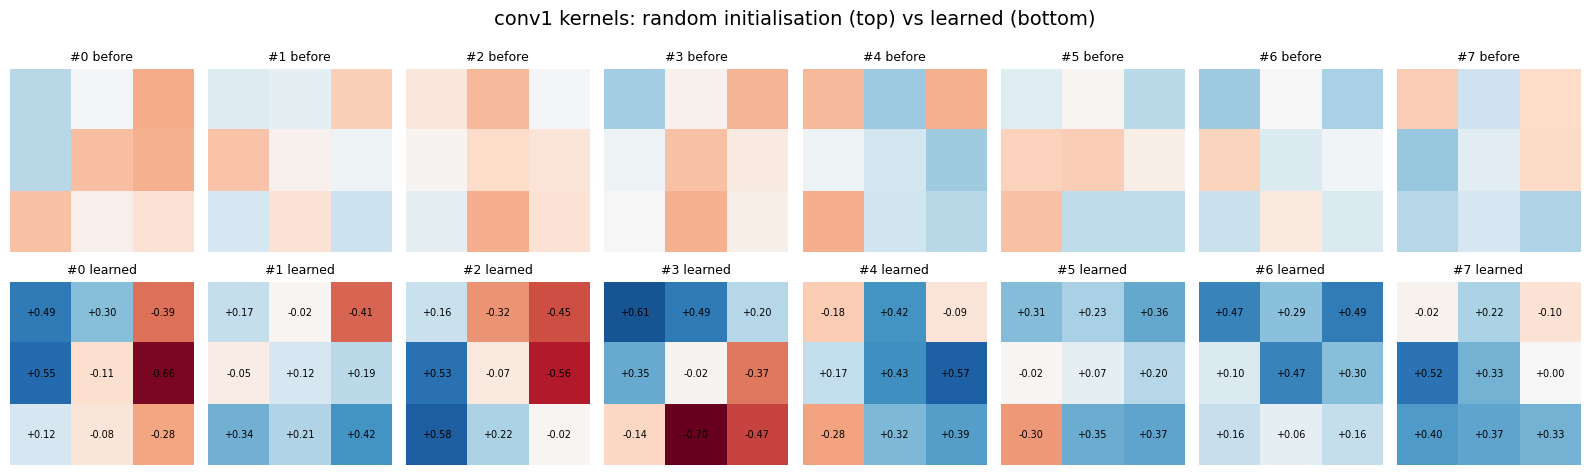

Weight magnitude, mean |w|:
  before training: 0.1395
  after  training: 0.2919


In [26]:
kernels_after = model.get_layer('conv1').get_weights()[0]     # (3, 3, 1, 8)

fig, axes = plt.subplots(2, 8, figsize=(16, 5))
fig.suptitle('conv1 kernels: random initialisation (top) vs learned (bottom)', fontsize=14)

vmax = max(np.abs(kernels_before).max(), np.abs(kernels_after).max())

for i in range(8):
    axes[0, i].imshow(kernels_before[:, :, 0, i], cmap='RdBu', vmin=-vmax, vmax=vmax)
    axes[0, i].set_title(f'#{i} before', fontsize=9)
    axes[0, i].axis('off')

    k = kernels_after[:, :, 0, i]
    axes[1, i].imshow(k, cmap='RdBu', vmin=-vmax, vmax=vmax)
    for (r, c), v in np.ndenumerate(k):
        axes[1, i].text(c, r, f'{v:+.2f}', ha='center', va='center', fontsize=7)
    axes[1, i].set_title(f'#{i} learned', fontsize=9)
    axes[1, i].axis('off')

plt.tight_layout(); plt.show()

print("Weight magnitude, mean |w|:")
print(f"  before training: {np.abs(kernels_before).mean():.4f}")
print(f"  after  training: {np.abs(kernels_after).mean():.4f}")

### Why we see this

**Before:** eight patches of random noise, all roughly the same magnitude, no structure.

**After:** structure appears. Look for kernels where one side is red and the other blue -
those are the network's own rediscovery of the edge detectors we hand-wrote in Step 6.
A kernel with a positive column beside a negative column *is* a vertical edge detector,
whether a human wrote it or gradient descent found it.

**They are not as clean as textbook kernels.** MNIST is easy and we only trained
5 epochs, so many kernels stay partly noisy - the network stopped improving them once
accuracy was already high. Compare the mean magnitudes printed below the figure: the
learned kernels are clearly larger than the random ones (about twice as large in our run), which is the
clearest single sign that training did something.

**Only conv1 kernels can be shown this way.** conv2's kernels are 3x3x8 cubes; there is
no honest way to draw one as a picture, which is another reason deeper layers resist
interpretation.

---
## Step 26 - One filter, many digits

Does a filter respond to a *pattern* rather than to a particular image? Pick one conv1
filter and apply it to several different digits.

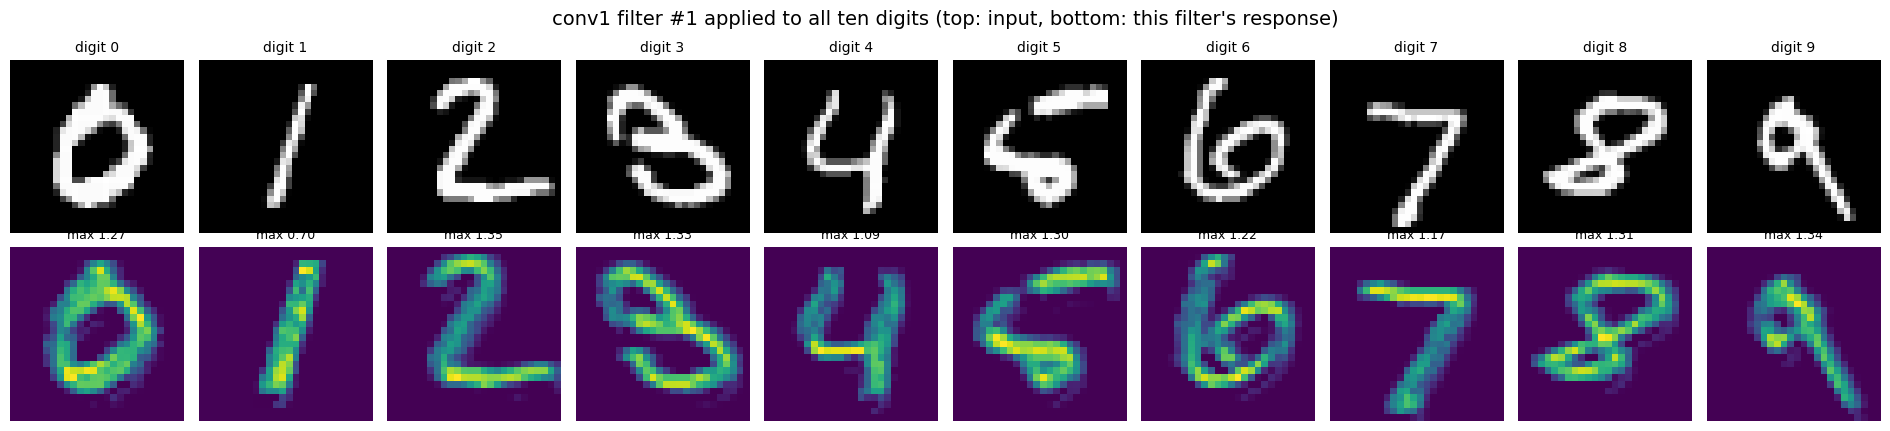

Filter #1's peak response per digit:
   digit 0:  1.27  ###############
   digit 1:  0.70  ########
   digit 2:  1.35  ################
   digit 3:  1.33  ###############
   digit 4:  1.09  #############
   digit 5:  1.30  ###############
   digit 6:  1.22  ##############
   digit 7:  1.17  ##############
   digit 8:  1.31  ###############
   digit 9:  1.34  ################


In [27]:
FILTER = 1          # <-- try changing this to any value 0-7

# Find one example of each digit 0-9
examples = [np.where(y_test == d)[0][0] for d in range(10)]
batch = x_test[examples]
acts_batch = get_all_activations(model, batch)['conv1']

fig, axes = plt.subplots(2, 10, figsize=(19, 4.4))
fig.suptitle(f'conv1 filter #{FILTER} applied to all ten digits '
             f'(top: input, bottom: this filter\'s response)', fontsize=14)

for d in range(10):
    axes[0, d].imshow(batch[d, :, :, 0], cmap='gray')
    axes[0, d].set_title(f'digit {d}', fontsize=10)
    axes[0, d].axis('off')

    resp = acts_batch[d, :, :, FILTER]
    axes[1, d].imshow(resp, cmap='viridis')
    axes[1, d].set_title(f'max {resp.max():.2f}', fontsize=9)
    axes[1, d].axis('off')

plt.tight_layout(); plt.show()

print(f"Filter #{FILTER}'s peak response per digit:")
for d in range(10):
    m = acts_batch[d, :, :, FILTER].max()
    print(f"   digit {d}: {m:5.2f}  {'#' * int(m*12)}")

### Why we see this

**The same 9 numbers were used on all ten images.** Nothing was re-tuned per digit -
this is parameter sharing in action.

**The filter responds wherever its pattern occurs**, and the pattern occurs in different
places in different digits. A filter that likes near-vertical strokes fires on the spine
of a `1`, on the left side of a `0`, and on the diagonal of a `7`.

**Response strength varies by digit, but never drops to nothing.** Look at the printed
peak responses: they typically span about a factor of two across the ten digits, with
sparse digits like `1` at the bottom simply because they contain less ink. The filter
never goes completely silent for any digit.

**That is the key limitation to understand.** A first-layer filter is a *general* stroke
detector, not a digit detector. On its own it cannot tell you which digit it is looking
at. Identity is assembled later, when conv2 and the Dense layer read the pattern of
*many* filters' responses together. Do not expect to find a "3 filter" in layer 1 - it
does not exist.

---
## Step 27 - ReLU and sparsity across the network

A quick quantitative look at how empty each layer's output is.

layer      shape                % zeros      mean       max
------------------------------------------------------------
conv1      (26, 26, 8)            51.1%     0.159     2.261
pool1      (13, 13, 8)            46.4%     0.238     2.261
conv2      (11, 11, 16)           56.7%     0.387     6.025
pool2      (5, 5, 16)             35.0%     0.856     6.025
flatten    (400,)                 35.0%     0.856     6.025
output     (10,)                   0.0%     0.100     1.000


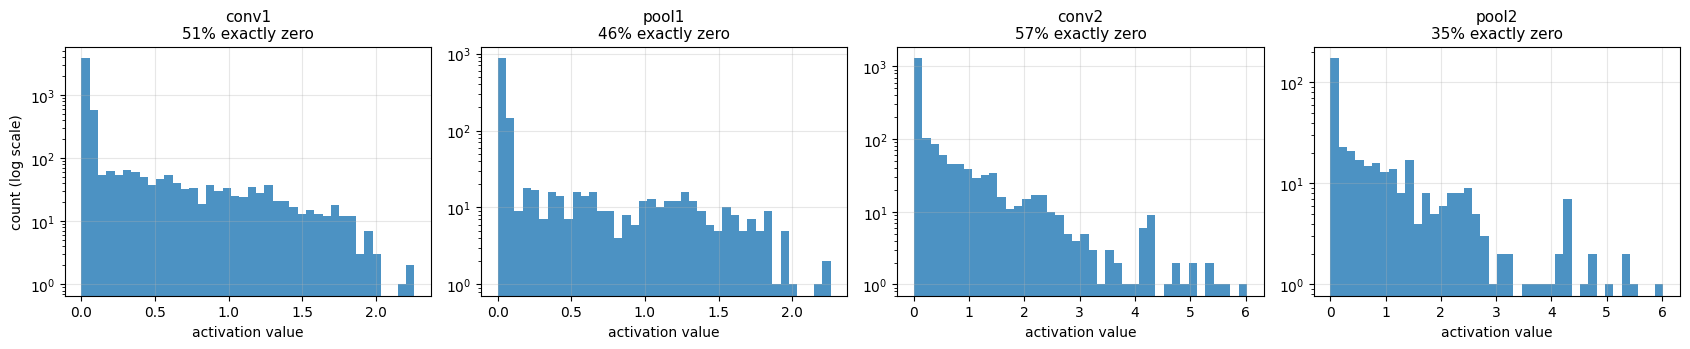

In [28]:
print(f"{'layer':<10} {'shape':<18} {'% zeros':>9} {'mean':>9} {'max':>9}")
print("-" * 60)
for name, a in activations.items():
    print(f"{name:<10} {str(a.shape[1:]):<18} "
          f"{100*np.mean(a==0):>8.1f}% {a.mean():>9.3f} {a.max():>9.3f}")

fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, name in zip(axes, ['conv1', 'pool1', 'conv2', 'pool2']):
    vals = activations[name].ravel()
    ax.hist(vals, bins=40, color='tab:blue', alpha=0.8)
    ax.set_title(f'{name}\n{100*np.mean(vals==0):.0f}% exactly zero', fontsize=11)
    ax.set_xlabel('activation value'); ax.set_yscale('log')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('count (log scale)')
plt.tight_layout(); plt.show()

### Why we see this

**Every histogram has a huge spike at exactly 0.** That is ReLU: `max(x, 0)` maps every
negative pre-activation to precisely zero. Nothing is ever negative after a ReLU - note
that the x-axis starts at 0. At initialisation roughly half of all pre-activations are
negative; after training the fraction settles wherever the task finds it useful, and here
the aggregate for conv1 typically lands somewhere near 40-50%.

**Pooling reduces the zero fraction.** pool1 is less sparse than conv1, because taking
the max of a 2x2 block only yields 0 if *all four* values were 0. Pooling keeps the
survivors.

**Sparsity is useful.** A layer where most units are silent is making a confident,
selective statement. It also means the network is not wasting capacity - each active unit
carries real information.

**One caution worth mentioning:** a unit that outputs zero for *every* input is a
**dead ReLU**. It cannot recover, because a zero output gives a zero gradient, so its
weights stop updating. This is one motivation for variants like LeakyReLU, which allow a
small negative slope.

---
# Part F - Wrapping up

---
## Step 28 - Summary

In [29]:
print("=" * 66)
print("WHAT WE BUILT".center(66))
print("=" * 66)
model.summary()
print("(After training, 'Total params' also counts the optimiser's memory: Adam keeps two running")
print(f" averages per weight, 2 x {model.count_params():,} = {2*model.count_params():,}, plus two counters. "
      "The model itself has only the trainable params.)")

print("\n" + "=" * 66)
print("KEY NUMBERS".center(66))
print("=" * 66)
print(f"  Parameters             : {model.count_params():,}")
print(f"  Accuracy before        : {acc_before*100:.2f}%")
print(f"  Accuracy after         : {test_acc*100:.2f}%")
print(f"  conv1 kernel shape     : (3, 3, 1, 8)   -> {8*(3*3*1+1)} params")
print(f"  conv2 kernel shape     : (3, 3, 8, 16)  -> {16*(3*3*8+1)} params")

print("\n" + "=" * 66)
print("THE FIVE IDEAS".center(66))
print("=" * 66)
print('''
1. INPUT SHAPE   Images keep their grid: (height, width, channels).
                 Grayscale needs an explicit channel of size 1.

2. KERNEL        A small grid of weights slid across the image.
                 Multiply-and-sum at every position. The SAME weights
                 everywhere - that is parameter sharing.

3. OUTPUT SHAPE  out = (in - k + 2p)/s + 1. With 3x3 valid padding you
                 lose 2 pixels. MaxPooling halves what remains.

4. CHANNELS      n_filters decides the OUTPUT channels. Every filter
                 spans ALL input channels: a filter is k x k x C_in.
                 params = n_filters x (k*k*C_in + 1).

5. FEATURE MAPS  Layer 1 finds edges and is readable. Deeper layers find
                 combinations and are not. Spatial size shrinks while
                 channel count grows.
''')

                          WHAT WE BUILT                           


Model: "tiny_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 26, 26, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 13, 13, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 11, 11, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         4,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,776 (61.63 KB)

 Trainable params: 5,258 (20.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 10,518 (41.09 KB)

(After training, 'Total params' also counts the optimiser's memory: Adam keeps two running
 averages per weight, 2 x 5,258 = 10,516, plus two counters. The model itself has only the trainable params.)

                           KEY NUMBERS                            
  Parameters             : 5,258
  Accuracy before        : 10.04%
  Accuracy after         : 98.26%
  conv1 kernel shape     : (3, 3, 1, 8)   -> 80 params
  conv2 kernel shape     : (3, 3, 8, 16)  -> 1168 params

                          THE FIVE IDEAS                          

1. INPUT SHAPE   Images keep their grid: (height, width, channels).
                 Grayscale needs an explicit channel of size 1.

2. KERNEL        A small grid of weights slid across the image.
                 Multiply-and-sum at every position. The SAME weights
                 everywhere - that is parameter sharing.

3. OUTPUT SHAPE  out = (in - k + 2p)/s + 1. With 3x3 valid padding you
                 lose 2 pixels. MaxPooling halves wha

---
## Exercises

Work through these by copying the relevant cells and modifying them.

**On shapes and kernels**

1. **Change the kernel size.** In Step 9 use `(5, 5)` instead of `(3, 3)`. Predict the new
   output shapes *before* running `model.summary()`, then check. How many parameters does
   conv1 have now, and why?
2. **Turn on padding.** Add `padding='same'` to both Conv2D layers. What are the shapes
   now? Why might you want this in a deep network?
3. **Use a stride.** Try `Conv2D(8, (3,3), strides=2)`. What replaces the pooling layer's
   job? What is lost?

**On channels**

4. **More filters.** Change conv1 to 16 filters and conv2 to 32. Work out the new
   parameter counts with the formula from Step 11 *before* running the code, then verify.
   Does accuracy improve enough to justify the extra cost?
5. **Predict a parameter count.** Without running anything: how many parameters would
   `Conv2D(64, (3,3))` have if its input had 32 channels? Then build it and check.

**On what the network learns**

6. **Explore other images.** Change `SAMPLE` in Step 18 to several different digits and
   re-run Steps 19-24. Which conv2 filters are selective - active for some digits and
   silent for others?
7. **Find a mistake.** Use the `wrong` array from Step 17 to pick a misclassified image,
   set `SAMPLE` to it, and study its feature maps and final probability bars. Was the
   network confidently wrong, or genuinely torn?
8. **Hand-designed vs learned.** Take your favourite learned kernel from Step 25, apply it
   to a digit with the `convolve2d` function from Step 6, and compare against the model's
   own conv1 feature map for that filter. They should match closely - if they do not,
   remember the bias term and the ReLU.

**Going deeper**

9. **Add a third conv layer.** Insert `Conv2D(32, (3,3), activation='relu')` after pool2.
   What goes wrong, and what does the error message tell you about the remaining spatial
   size? (Hint: 5x5 cannot survive many more valid convolutions.)
10. **Compare against Lab 01.** Build a Dense-only network with a comparable parameter
    count and train it on all 10 digits. Which wins, and by how much?

---
### Credits and further reading

- MNIST: LeCun, Cortes and Burges, *The MNIST Database of Handwritten Digits*.
- The convolution-as-learned-filter idea traces back to LeCun et al., *Gradient-Based
  Learning Applied to Document Recognition* (1998) - the LeNet paper.
- Keras documentation: `Conv2D`, `MaxPooling2D` - https://keras.io/api/layers/

Built as a companion to **Lab 01 - Is this digit a 3?**